| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../10_OPTIMIZACION/10_1_Optimizacion_matematica.ipynb) | [⏩](../10_OPTIMIZACION/10_3_Segundo_orden.ipynb) |

# 10.2 Métodos de gradiente: paso, condicionamiento y ruido

**Objetivo del cuaderno.** implementar descenso de gradiente, explicar su estabilidad, comparar búsqueda de paso y entrenamiento estocástico

**Antes de empezar:** gradiente, matrices simétricas y mínimos cuadrados. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)

## 1. La dirección de máximo descenso local

Para un desplazamiento pequeño $p$, $J(\theta+p)\approx J(\theta)+\nabla J(\theta)^Tp$. Entre las direcciones de norma uno, $-\nabla J/\|\nabla J\|$ produce la reducción lineal más grande. Por eso el método básico es

$$\theta_{n+1}=\theta_n-\eta\nabla J(\theta_n),\qquad \eta>0.$$

Esta es una afirmación local; un paso demasiado largo puede aumentar $J$. La tasa de aprendizaje $\eta$ determina cuánto confiamos en la aproximación lineal.

## 2. Hipótesis que permiten una garantía

Si $\nabla J$ es Lipschitz con constante $L$, se cumple el lema de descenso:

$$J(\theta-\eta g)\le J(\theta)-\eta(1-L\eta/2)\|g\|^2.$$

Para $0<\eta<2/L$ el término de reducción es positivo si $g\ne0$. En una cuadrática definida positiva, $L=\lambda_{\max}(A)$ y la dinámica del error es $e_{n+1}=(I-\eta A)e_n$. Cada autocomponente se multiplica por $1-\eta\lambda_j$; la condición exacta de convergencia es $|1-\eta\lambda_j|<1$ para todos los autovalores.

## 3. Implementación transparente

La rutina guarda cada iteración para observar trayectorias y utiliza una norma de gradiente como criterio de parada. El presupuesto máximo evita bucles indefinidos. En aplicaciones grandes no suele ser necesario guardar todo el historial.

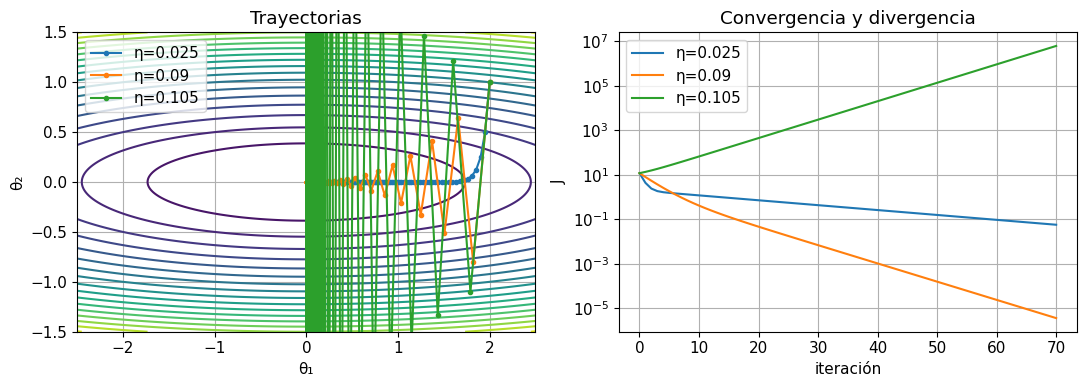

In [2]:
A = np.diag([1., 20.])
def objective(z): return 0.5*z @ A @ z
def gradient(z): return A @ z
def descent(x0, eta, steps=70):
    x = np.asarray(x0, dtype=float).copy(); history = [x.copy()]
    for _ in range(steps):
        g = gradient(x)
        if np.linalg.norm(g) < 1e-9: break
        x -= eta*g; history.append(x.copy())
    return np.array(history)
paths = {eta: descent([2., 1.], eta) for eta in [0.025, 0.09, 0.105]}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
u,v = np.meshgrid(np.linspace(-2.5,2.5,200),np.linspace(-1.5,1.5,200))
ax[0].contour(u,v,0.5*(u*u+20*v*v),levels=20)
for eta,path in paths.items():
    ax[0].plot(path[:,0],path[:,1],'.-',label=f'η={eta}')
    ax[1].semilogy([objective(q) for q in path],label=f'η={eta}')
ax[0].set(xlim=(-2.5,2.5),ylim=(-1.5,1.5),xlabel='θ₁',ylabel='θ₂',title='Trayectorias')
ax[1].set(xlabel='iteración',ylabel='J',title='Convergencia y divergencia')
for a in ax:a.legend()
plt.tight_layout();plt.show()

**Interpretación.** El límite es $2/20=0.1$. El paso 0.105 vuelve inestable la componente de mayor curvatura. Un paso pequeño elimina el riesgo de esta inestabilidad, pero ralentiza el avance en la dirección de menor curvatura. Las oscilaciones con 0.09 se explican por un multiplicador negativo, próximo a $-1$, en la segunda dirección.

## 4. Condicionamiento y precondicionamiento

El número de condición $\kappa=L/\mu$ compara las curvaturas extrema mayor y menor. Si es grande, un único paso debe ser pequeño para estabilizar la dirección rígida y resulta lento para la dirección plana. Para una cuadrática el paso constante óptimo, en el peor caso espectral, es $2/(L+\mu)$ y el factor de contracción es $(\kappa-1)/(\kappa+1)$.

Precondicionar significa cambiar la geometría del paso:

$$\theta_{n+1}=\theta_n-\eta P\nabla J(\theta_n),$$

con $P$ definida positiva. Una matriz diagonal que corrige escalas puede acelerar mucho. Usar $P=A^{-1}$ resuelve esta cuadrática en un paso con $\eta=1$; en problemas generales esa matriz no suele ser conocida ni barata.

Condición A: 20.0


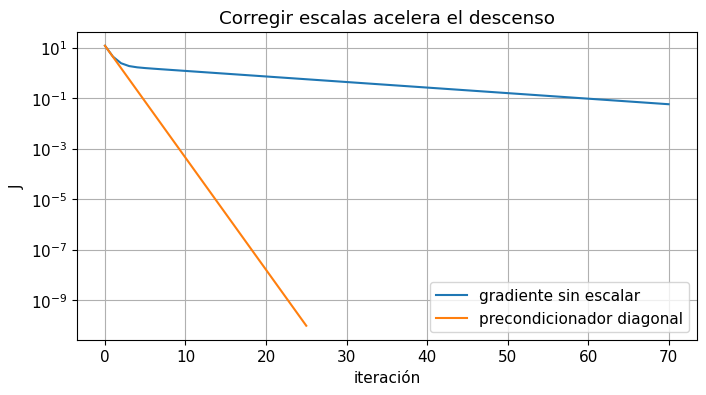

In [3]:
x = np.array([2., 1.]); pre_path=[x.copy()]
P = np.diag(1/np.diag(A))
for _ in range(25):
    x -= 0.4*(P @ gradient(x)); pre_path.append(x.copy())
pre_path=np.array(pre_path)
plt.semilogy([objective(q) for q in paths[0.025]],label='gradiente sin escalar')
plt.semilogy([objective(q) for q in pre_path],label='precondicionador diagonal')
plt.xlabel('iteración');plt.ylabel('J');plt.title('Corregir escalas acelera el descenso');plt.legend();plt.show()
print('Condición A:', np.linalg.cond(A))
assert objective(pre_path[-1]) < objective(paths[0.025][-1])

## 5. Búsqueda de paso por Armijo

Cuando $L$ es desconocida, una búsqueda retrospectiva prueba $\eta=1$ y lo reduce hasta cumplir

$$J(\theta-\eta g)\le J(\theta)-c\eta\|g\|^2,\quad 0<c<1.$$

La condición exige reducción suficiente en relación con la predicción lineal. Es útil con objetivos deterministas. Con minibatches diferentes en cada evaluación la comparación se contamina con ruido; por ello la misma lógica no debe trasladarse sin cuidado al entrenamiento estocástico.

In [4]:
def armijo_descent(x0, steps=70, c=1e-4, reduction=0.5):
    x=np.array(x0,dtype=float); hist=[x.copy()]; accepted=[]
    for _ in range(steps):
        g=gradient(x)
        if np.linalg.norm(g)<1e-9:break
        eta=1.
        while objective(x-eta*g)>objective(x)-c*eta*(g@g):
            eta*=reduction
            if eta<1e-14:raise RuntimeError('Paso demasiado pequeño')
        x -= eta*g;hist.append(x.copy());accepted.append(eta)
    return np.array(hist),np.array(accepted)
arm_path,used_steps=armijo_descent([2.,1.])
print('Objetivo final Armijo:',objective(arm_path[-1]))
print('Primeros pasos aceptados:',used_steps[:10])
assert np.all(np.diff([objective(q) for q in arm_path]) <= 1e-12)

Objetivo final Armijo: 2.7196157011457644e-08
Primeros pasos aceptados: [0.0625 0.0625 0.25   0.0625 0.125  0.125  0.0625 0.125  0.125  0.0625]


## 6. Gradiente estocástico: estimar en lugar de sumar todo

Si $J(\theta)=n^{-1}\sum_i\ell_i(\theta)$, un minibatch uniforme $B$ produce

$$g_B=|B|^{-1}\sum_{i\in B}\nabla\ell_i(\theta),\quad \mathbb E[g_B\mid\theta]=\nabla J(\theta).$$

La igualdad supone muestreo apropiado; el barajado sin reemplazo tiene detalles distintos durante una época. Una época procesa aproximadamente todos los datos; una iteración hace una actualización. SGD abarata cada actualización y añade variabilidad. No esperamos que la pérdida completa disminuya en cada paso.

Usamos regresión $y=2x-0.5+\epsilon$. Para una fila $a_i=[1,x_i]$, la pérdida media $\tfrac12(a_i^T\theta-y_i)^2$ tiene gradiente $a_i(a_i^T\theta-y_i)$.

SGD 1, fijo [-0.51793  1.97139]
minibatch 16 [-0.50086  2.00531]
SGD 1, decreciente [-0.50304  2.00304]
Referencia: [-0.50135  1.99895]


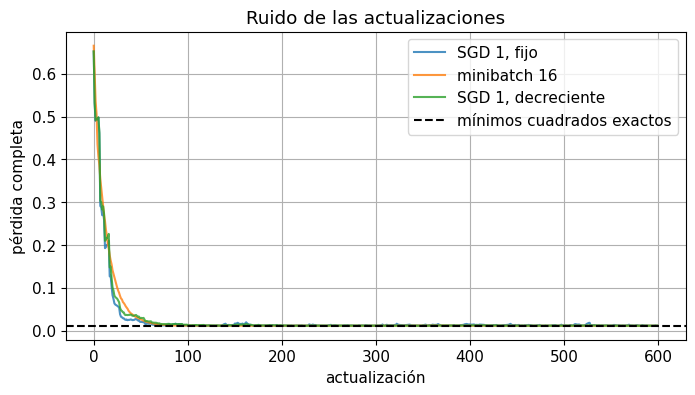

In [5]:
x_data = rng.uniform(-1,1,120)
y_data = 2*x_data-0.5+rng.normal(0,0.15,120)
D=np.column_stack([np.ones(len(x_data)),x_data])
theta_ls=np.linalg.lstsq(D,y_data,rcond=None)[0]
def mse_half(theta):return np.mean((D@theta-y_data)**2)/2
def train_sgd(batch_size,decay,steps=600):
    theta=np.zeros(2);hist=[]
    local_rng=np.random.default_rng(10)
    for k in range(steps):
        ids=local_rng.choice(len(D),size=batch_size,replace=False)
        g=D[ids].T@(D[ids]@theta-y_data[ids])/batch_size
        eta=0.12/(1+decay*k)
        theta-=eta*g;hist.append(mse_half(theta))
    return theta,np.array(hist)
experiments={}
for label,batch,decay in [('SGD 1, fijo',1,0),('minibatch 16',16,0),('SGD 1, decreciente',1,0.01)]:
    experiments[label]=train_sgd(batch,decay)
    plt.plot(experiments[label][1],label=label,alpha=0.8)
plt.axhline(mse_half(theta_ls),c='k',ls='--',label='mínimos cuadrados exactos')
plt.xlabel('actualización');plt.ylabel('pérdida completa');plt.title('Ruido de las actualizaciones');plt.legend();plt.show()
for name,(th,_) in experiments.items():print(name,th)
print('Referencia:',theta_ls)

**Interpretación.** Un minibatch mayor reduce las fluctuaciones de este problema. Un paso decreciente facilita acercarse al mínimo, aunque puede ralentizar el aprendizaje temprano. La comparación está hecha por actualización: no es una comparación justa de tiempo ni de número de ejemplos procesados, porque los tamaños de batch difieren.

## 7. Momentum y Adam: memoria de los gradientes

Momentum mantiene $v_{n+1}=\beta v_n+g_n$ y actualiza $\theta_{n+1}=\theta_n-\eta v_{n+1}$. Promedia direcciones recientes y puede acelerar valles alargados; los parámetros también pueden generar oscilaciones.

Adam utiliza promedios exponenciales del gradiente y su cuadrado, con corrección de sesgo:

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,$$
$$\theta_t=\theta_{t-1}-\eta\frac{m_t/(1-\beta_1^t)}{\sqrt{v_t/(1-\beta_2^t)}+\epsilon}.$$

Las operaciones de Adam son componente a componente. No es equivalente a Newton ni garantiza por sí solo un mínimo global. Sus escalas adaptativas suelen ser prácticas en redes, pero la selección de tasa, regularización y pérdida sigue siendo esencial.

## 8. Verificar la derivada antes de entrenar

Un gradiente incorrecto puede producir pérdidas que parecen reducirse durante algunos pasos. Comprobamos una derivada direccional mediante diferencias centrales. La discrepancia debe evaluarse con escala relativa y un rango razonable de pasos, porque pasos extremadamente pequeños amplifican redondeo.

In [6]:
theta=np.array([0.3,-0.8]);direction=np.array([0.6,0.8]);h=1e-5
analytic=gradient(theta)@direction
numeric=(objective(theta+h*direction)-objective(theta-h*direction))/(2*h)
print('Derivada analítica / numérica:',analytic,numeric)
assert np.isclose(analytic,numeric,rtol=1e-7,atol=1e-8)
print('Gradiente del ajuste LS:',np.linalg.norm(D.T@(D@theta_ls-y_data)/len(D)))

Derivada analítica / numérica: -12.620000000000001 -12.619999999996521
Gradiente del ajuste LS: 3.3506903800835603e-16


## 9. Parar por una razón interpretable

Una diferencia de pérdidas diminuta puede significar convergencia, un paso demasiado pequeño o una región plana. Una norma de gradiente pequeña puede coexistir con un punto silla. Utiliza conjuntamente presupuesto, norma, reducción y validación. En entrenamiento con ruido conviene evaluar por épocas y guardar el modelo con mejor pérdida de validación.

## 10. Gradientes en SciML

Un residual físico $r_\theta=u_t-\alpha u_{xx}$ tiene derivadas de orden distinto y puede generar gradientes con escalas muy dispares. Cambiar los pesos de las pérdidas cambia la función objetivo; cambiar el precondicionador cambia cómo recorremos esa función. Son decisiones conceptualmente diferentes. Antes de cambiar de optimizador, revisa unidades, normalización y exactitud de derivadas.

## Síntesis y conexión con Scientific Machine Learning

La tasa de aprendizaje está relacionada con la curvatura y la estabilidad. Armijo controla el descenso determinista; minibatches reducen coste a cambio de ruido. En modelos científicos conviene verificar gradientes, escalar parámetros y distinguir velocidad de optimización de calidad predictiva.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../10_OPTIMIZACION/10_1_Optimizacion_matematica.ipynb) | [⏩](../10_OPTIMIZACION/10_3_Segundo_orden.ipynb) |